# Fase 3 · Modify: preparación y transformación de datos

Esta fase convierte los registros del dataset en una representación numérica que un algoritmo de clasificación pueda usar. Todo el procesamiento está en código reutilizable y no en el notebook:

- `vulnminer/features.py` contiene la limpieza, el tokenizador, los indicadores de seguridad y la definición del pipeline. La herramienta CLI importará este mismo módulo para transformar los proyectos que analice, de modo que el código nuevo reciba exactamente el mismo tratamiento que los datos de entrenamiento.
- `scripts/preprocesar.py` aplica el pipeline al dataset y guarda las matrices resultantes.

Aquí se recorre el proceso paso a paso para mostrar qué hace cada transformación y por qué.

In [1]:
import json
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import sparse

RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ))
sys.path.insert(0, str(RAIZ / "scripts"))
sys.path.insert(0, str(Path.cwd()))

import estilo
import preprocesar
from vulnminer.features import NOMBRES_INDICADORES, extraer_indicadores, limpiar_codigo, tokenizar_codigo

estilo.aplicar()
FIG = RAIZ / "reports" / "figures"
df = preprocesar.cargar()
print(len(df), "registros cargados")

1541 registros cargados


## 1. Validación y limpieza de registros

Primero se descartan registros incompletos o con etiquetas incoherentes: código vacío, una etiqueta binaria distinta de 0 o 1, un ejemplo vulnerable sin categoría OWASP o uno seguro con categoría. El análisis exploratorio no encontró ninguno, pero la validación queda en el pipeline para que cualquier ampliación futura del dataset pase por el mismo filtro.

In [2]:
df, invalidos = preprocesar.validar(df)
print("Registros descartados por validación:", len(invalidos))

Registros descartados por validación: 0


## 2. Normalización del código

La limpieza resuelve los problemas de calidad detectados en la fase Explore. Se eliminan los comentarios, incluidas las cabeceras de licencia y los comentarios explicativos de los casos controlados, y se reemplazan los nombres de categoría que Benchmark coloca en las rutas y los identificadores numéricos de cada caso. Los literales de relleno de Benchmark (`This_should_always_happen`, `bobs_your_uncle`, `safe`...) y los mensajes que repiten la etiqueta se sustituyen por `"CONST"`. Así el modelo todavía ve que el dato del usuario fue reemplazado por una constante, que es una señal legítima de flujo de datos, pero ya no puede reconocer qué cadena concreta usa Benchmark en sus casos seguros. También se uniforman los saltos de línea, las tabulaciones y las líneas en blanco.

La eliminación de comentarios respeta las cadenas de texto. No basta con borrar todo lo que sigue a `//`, porque eso también cortaría una URL como `"http://servicio:8080"`.

In [3]:
fila = df[df.proyecto_origen == "BenchmarkPython"].iloc[3]
print("ANTES (primeras 28 líneas)\n" + "\n".join(fila.codigo.splitlines()[:28]))
print("\n" + "=" * 70 + "\nDESPUÉS (primeras 14 líneas)\n")
print("\n".join(limpiar_codigo(fila.codigo, fila.tipo_archivo).splitlines()[:14]))

ANTES (primeras 28 líneas)
'''
OWASP Benchmark for Python v0.1

This file is part of the Open Web Application Security Project (OWASP) Benchmark Project.
For details, please see https://owasp.org/www-project-benchmark.

The OWASP Benchmark is free software: you can redistribute it and/or modify it under the terms
of the GNU General Public License as published by the Free Software Foundation, version 3.

The OWASP Benchmark is distributed in the hope that it will be useful, but WITHOUT ANY
WARRANTY; without even the implied warranty of MERCHANTABILITY or FITNESS FOR A PARTICULAR
PURPOSE. See the GNU General Public License for more details.

  Author: Theo Cartsonis
  Created: 2025
'''

from flask import redirect, url_for, request, make_response, render_template
from helpers.utils import escape_for_html

def init(app):

	@app.route('/benchmark/sqli-00/BenchmarkTest00011', methods=['GET'])
	def BenchmarkTest00011_get():
		response = make_response(render_template('web/sqli-00/BenchmarkTest

In [4]:
df = preprocesar.limpiar(df)
fuga = r"(?:cmdi|crypto|hash|ldapi|pathtraver|securecookie|sqli|trustbound|weakrand|xpathi|xss|codeinj|deserialization|redirect|xxe)-\d\d"
print("Registros que aún contienen el nombre de categoría en rutas:", df.codigo_limpio.str.contains(fuga).sum())
print("Registros que aún contienen la licencia:", df.codigo_limpio.str.contains("General Public License").sum())
print("Registros que aún contienen literales de relleno:", df.codigo_limpio.str.contains(r"[\"'](?:This_should_always_happen|bobs_your_uncle|safe|a_Value)[\"']").sum())
print(f"Longitud media: {df.codigo.str.len().mean():.0f} -> {df.codigo_limpio.str.len().mean():.0f} caracteres")

Registros que aún contienen el nombre de categoría en rutas: 0
Registros que aún contienen la licencia: 0
Registros que aún contienen literales de relleno: 0
Longitud media: 2235 -> 1697 caracteres


Después de normalizar, dos fragmentos que antes se distinguían solo por un comentario o un identificador podrían quedar idénticos. Si eso ocurre con etiquetas distintas se eliminan ambos, porque no hay forma de saber cuál es correcta; si las etiquetas coinciden se conserva uno solo, dando preferencia al que está en entrenamiento para no dejar en evaluación código que el modelo ya vio.

In [5]:
df, n_conflicto, n_duplicados = preprocesar.deduplicar(df)
print("Eliminados por etiqueta en conflicto:", n_conflicto)
print("Duplicados eliminados tras normalizar:", n_duplicados)
print("Registros restantes:", len(df))

Eliminados por etiqueta en conflicto: 0
Duplicados eliminados tras normalizar: 0
Registros restantes: 1541


No apareció ningún duplicado nuevo: los casos de Benchmark difieren en su lógica y los casos controlados en las entidades y rutas con que se instanciaron.

## 3. Normalización de las etiquetas

Las columnas `owasp2025` y `api2023` se unen en una lista de etiquetas por registro y se convierten en una matriz binaria con una columna por cada una de las veinte categorías, más la columna `vulnerable`. Este es el formato que necesita un clasificador multietiqueta, ya que un mismo hallazgo puede pertenecer a ambos estándares a la vez (por ejemplo, una SSRF es A01:2025 y API7:2023). Las categorías sin ejemplos quedan como columnas en cero, para que el catálogo esté completo.

In [6]:
df, Y = preprocesar.normalizar_etiquetas(df)
print("Registros con más de una etiqueta:", (Y.drop(columns="vulnerable").sum(axis=1) > 1).sum())
Y.sum().to_frame("positivos").T

Registros con más de una etiqueta: 198


,A01:2025,A02:2025,A03:2025,A04:2025,A05:2025,A06:2025,A07:2025,A08:2025,A09:2025,A10:2025,...,API2:2023,API3:2023,API4:2023,API5:2023,API6:2023,API7:2023,API8:2023,API9:2023,API10:2023,vulnerable
positivos,127,92,14,131,219,63,34,37,25,30,...,40,19,20,19,0,20,55,0,0,772


## 4. Tokenización

El código no se puede tokenizar como texto en lenguaje natural. El tokenizador propio separa identificadores, números, versiones y algunos símbolos relevantes para seguridad (`+`, `*`, `%`, `?`, `!`, `${`). Los identificadores compuestos se guardan completos y además divididos en subpalabras, para que `executeQuery`, `execute_query` y `query` compartan información. Los números se reemplazan por `NUM` porque su valor concreto rara vez importa; en cambio, las versiones (`2.14.1`) se conservan, porque en un archivo de dependencias son justamente lo que indica el riesgo.

In [7]:
ejemplos = [
    'String sql = "SELECT * FROM users WHERE id=" + userId;',
    'payload = jwt.decode(token, options={"verify_signature": False})',
    'log4j-core 2.14.1   password: ${DB_PASSWORD}',
]
for e in ejemplos:
    print(e, "\n   ->", tokenizar_codigo(e), "\n")

String sql = "SELECT * FROM users WHERE id=" + userId; 
   -> ['string', 'sql', 'select', '*', 'from', 'users', 'where', 'id', '+', 'userid', 'user', 'id'] 

payload = jwt.decode(token, options={"verify_signature": False}) 
   -> ['payload', 'jwt', 'decode', 'token', 'options', 'verify_signature', 'verify', 'signature', 'false'] 

log4j-core 2.14.1   password: ${DB_PASSWORD} 
   -> ['log4j', 'core', 'VER_2_14_1', 'password', '${', 'db_password', 'db', 'password'] 



## 5. Extracción de características

Cada fragmento se representa con tres bloques de características que luego se concatenan.

El primero es **TF-IDF** sobre los tokens anteriores, con unigramas y bigramas, un mínimo de dos documentos por término y un máximo de 5000 términos. Los bigramas permiten capturar combinaciones como `parseclaimsjwt token` o `setsecure false`, que dicen mucho más que cada palabra por separado. Se usa escala sublineal de frecuencias para que un término repetido muchas veces en un archivo largo no domine.

El segundo bloque son **indicadores de seguridad**: conteos de patrones relacionados con las características sugeridas en el enunciado, como consultas dinámicas, autenticación y autorización, validación de entradas, criptografía, manejo de excepciones, configuración, tokens y credenciales, endpoints REST y dependencias. Se escalan con `MaxAbsScaler` para llevarlos a un rango comparable con TF-IDF sin destruir la dispersión de la matriz. Estos indicadores no asignan una categoría OWASP; son variables de entrada cuyo peso aprenderá el modelo. La longitud del fragmento no se incluye, por el sesgo descrito en la fase Explore.

El tercero es el **tipo de archivo** codificado en one-hot, porque un mismo token (por ejemplo `debug`) significa cosas distintas en un `.properties` y en un `.java`.

In [8]:
fila = df[df.categoria_vuln == "ssrf"].iloc[0]
print(fila.codigo_limpio)
valores = pd.Series(extraer_indicadores(fila.codigo_limpio), index=NOMBRES_INDICADORES)
valores[valores > 0].to_frame("valor").T

package com.example.payment;

@RestController
@RequestMapping("/api/v1/profiles")
public class ProfilePreviewController {
    private final RestTemplate restTemplate = new RestTemplate();

    @GetMapping("/preview")
    public String preview(@RequestParam String url) {
        return restTemplate.getForObject(url, String.class);
    }
}



,entrada_usuario,endpoints,peticion_saliente
valor,1,2,4


Los 46 indicadores se agrupan así según la característica sugerida que representan:

In [9]:
grupos = {
    "Consultas dinámicas y ejecución": ["sql_dinamico", "sql_parametrizado", "ejecucion_comandos", "shell_activado", "evaluacion_dinamica", "deserializacion", "parser_xml"],
    "Criptografía": ["cripto_debil", "cripto_fuerte", "aleatorio_inseguro", "aleatorio_seguro"],
    "Autenticación y autorización": ["control_roles", "usuario_autenticado", "verificacion_propietario", "limite_intentos"],
    "Tokens y credenciales": ["uso_jwt", "jwt_sin_verificar", "credencial_literal", "variable_entorno", "cookies", "cookie_segura", "cookie_no_segura"],
    "Validación de entradas": ["validacion_entrada", "entrada_usuario", "asignacion_dinamica"],
    "Rutas y endpoints REST": ["endpoints", "parametro_ruta", "peticion_saliente", "validacion_url", "redireccion", "consulta_completa", "paginacion", "limite_maximo"],
    "Errores y excepciones": ["bloques_excepcion", "excepcion_expuesta", "excepcion_silenciada"],
    "Registro de eventos": ["registro_eventos", "registro_concatenado", "registro_sensible"],
    "Configuración y contenedores": ["modo_debug", "cors_abierto", "exposicion_diagnostico", "contenedor_privilegiado", "imagen_sin_version", "endurecimiento_contenedor"],
    "Dependencias": ["dependencias_declaradas"],
}
assert sorted(sum(grupos.values(), [])) == sorted(NOMBRES_INDICADORES)
pd.DataFrame([(g, len(v), ", ".join(v)) for g, v in grupos.items()], columns=["grupo", "n", "indicadores"])

,grupo,n,indicadores
0,Consultas dinámicas y ejecución,7,"sql_dinamico, sql_parametrizado, ejecucion_com..."
1,Criptografía,4,"cripto_debil, cripto_fuerte, aleatorio_insegur..."
2,Autenticación y autorización,4,"control_roles, usuario_autenticado, verificaci..."
3,Tokens y credenciales,7,"uso_jwt, jwt_sin_verificar, credencial_literal..."
4,Validación de entradas,3,"validacion_entrada, entrada_usuario, asignacio..."
5,Rutas y endpoints REST,8,"endpoints, parametro_ruta, peticion_saliente, ..."
6,Errores y excepciones,3,"bloques_excepcion, excepcion_expuesta, excepci..."
7,Registro de eventos,3,"registro_eventos, registro_concatenado, regist..."
8,Configuración y contenedores,6,"modo_debug, cors_abierto, exposicion_diagnosti..."
9,Dependencias,1,dependencias_declaradas


## 6. Construcción de la matriz de características

El pipeline completo es un `ColumnTransformer` de scikit-learn. Se ajusta **solo con el conjunto de entrenamiento**: el vocabulario de TF-IDF, los pesos IDF y las escalas de los indicadores se calculan sobre train y después se aplican sin cambios a validación y prueba. Si se ajustara con todo el dataset, información de prueba (por ejemplo, qué términos existen en ella) se filtraría al modelo y la evaluación sería optimista.

El script `preprocesar.py` ejecuta todos los pasos anteriores, ajusta el pipeline y guarda los resultados. Se ejecuta aquí para que el notebook refleje los archivos actuales.

In [10]:
preprocesar.main()

{
  "registros_iniciales": 1541,
  "descartados_por_validacion": 0,
  "descartados_por_conflicto_de_etiqueta": 0,
  "duplicados_tras_normalizar": 0,
  "registros_finales": 1541,
  "por_particion": {
    "train": 1031,
    "val": 247,
    "test": 263
  },
  "caracteristicas_por_bloque": {
    "tfidf": 5000,
    "ind": 46,
    "tipo": 8
  },
  "caracteristicas_totales": 5054,
  "minimo_por_estrato_tras_balanceo": 17,
  "train_balanceado": 1177
}


In [11]:
SALIDA = RAIZ / "data" / "processed"
X = {p: sparse.load_npz(SALIDA / f"X_{p}.npz") for p in ("train", "val", "test")}
Yp = {p: pd.read_csv(SALIDA / f"Y_{p}.csv") for p in ("train", "val", "test")}
nombres = (SALIDA / "nombres_caracteristicas.txt").read_text(encoding="utf-8").splitlines()

pd.DataFrame({
    "filas": {p: m.shape[0] for p, m in X.items()},
    "columnas": {p: m.shape[1] for p, m in X.items()},
    "densidad_%": {p: round(100 * m.nnz / (m.shape[0] * m.shape[1]), 2) for p, m in X.items()},
    "vulnerables": {p: int(y.vulnerable.sum()) for p, y in Yp.items()},
})

,filas,columnas,densidad_%,vulnerables
train,1031,5054,4.99,519
val,247,5054,4.60,126
test,263,5054,4.27,127


La matriz tiene 5054 columnas: 5000 de TF-IDF, 46 indicadores y 8 tipos de archivo. Solo alrededor del 5 % de sus celdas son distintas de cero, por lo que se guarda en formato disperso (`.npz`). Los términos de TF-IDF con mayor peso promedio en entrenamiento son estos:

In [12]:
tfidf = slice(0, 5000)
pesos = np.asarray(X["train"][:, tfidf].mean(axis=0)).ravel()
orden = np.argsort(pesos)[::-1][:20]
pd.DataFrame({"termino": [nombres[i].replace("tfidf__", "") for i in orden], "peso_medio": pesos[orden].round(4)}).T

,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
termino,benchmark,test,response,benchmark test,NUM,import,request,param,get,servlet,bar,benchmarktest benchmark,benchmarktest,string,http,app,exception,def,post,http servlet
peso_medio,0.0442,0.0441,0.0433,0.0408,0.0407,0.0388,0.0383,0.038,0.0359,0.0358,0.034,0.032,0.032,0.0316,0.0315,0.031,0.0294,0.0293,0.029,0.0281


Los términos con más peso medio (`benchmark`, `test`, `servlet`, `param`, `bar`) son el andamiaje común de los casos de Benchmark y no dicen nada sobre seguridad; simplemente identifican la fuente. Como dentro de cada fuente las clases están equilibradas, no revelan la etiqueta, pero confirman el riesgo señalado en la fase Explore. En la fase Model habrá que revisar qué características usa realmente el modelo para decidir y, si estos términos pesan demasiado, añadirlos a una lista de palabras excluidas.

## 7. Tratamiento del desbalance

Como se vio en la fase Explore, las clases binarias están equilibradas pero las categorías no. Se probó una estrategia conservadora: sobremuestreo aleatorio (`RandomOverSampler`) de los estratos (tipo de vulnerabilidad, clase) del conjunto de entrenamiento que tienen menos ejemplos que la mediana de estratos. Se duplican filas completas, así que cada copia conserva todas sus etiquetas.

No se usó SMOTE porque genera puntos interpolados entre dos ejemplos, y en una matriz TF-IDF de código eso produce vectores que no corresponden a ningún programa posible. Tampoco se sobremuestrea hasta igualar todos los estratos, porque duplicar muchas veces los pocos ejemplos de una categoría pequeña favorece el sobreajuste.

Se guardan las dos versiones del conjunto de entrenamiento (original y balanceada). En la fase Model se compararán contra la alternativa de usar pesos por clase, que no modifica los datos. Validación y prueba nunca se balancean, porque deben reflejar la distribución real.

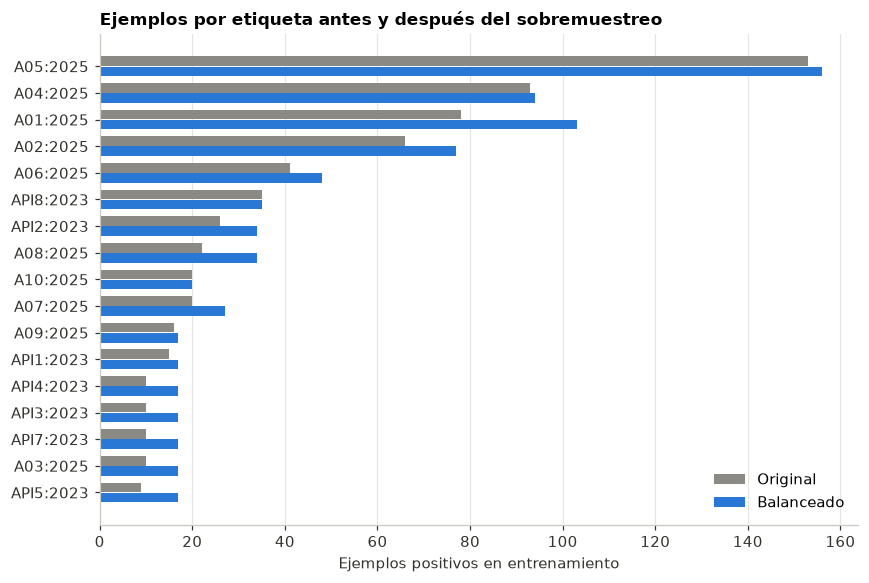

Mínimo por estrato: 17; filas de entrenamiento: 1031 -> 1177


,API5:2023,A03:2025,API7:2023,API3:2023,API4:2023,API1:2023,A09:2025,A07:2025,A10:2025,A08:2025,API2:2023,API8:2023,A06:2025,A02:2025,A01:2025,A04:2025,A05:2025
original,9,10,10,10,10,15,16,20,20,22,26,35,41,66,78,93,153
balanceado,17,17,17,17,17,17,17,27,20,34,34,35,48,77,103,94,156


In [13]:
resumen = json.loads((SALIDA / "resumen_preprocesamiento.json").read_text(encoding="utf-8"))
Y_bal = pd.read_csv(SALIDA / "Y_train_bal.csv")
etiquetas = [c for c in Yp["train"].columns if c != "vulnerable" and Yp["train"][c].sum() > 0]
comparacion = pd.DataFrame({"original": Yp["train"][etiquetas].sum(), "balanceado": Y_bal[etiquetas].sum()})

fig, ax = plt.subplots(figsize=(8, 5.4))
comparacion = comparacion.sort_values("original")
y = np.arange(len(comparacion))
alto = 0.36
ax.barh(y + alto / 2 + 0.01, comparacion["original"], height=alto, color=estilo.GRIS, label="Original")
ax.barh(y - alto / 2 - 0.01, comparacion["balanceado"], height=alto, color=estilo.AZUL, label="Balanceado")
ax.set_yticks(y, comparacion.index)
ax.set_xlabel("Ejemplos positivos en entrenamiento")
ax.set_title("Ejemplos por etiqueta antes y después del sobremuestreo", loc="left")
ax.legend(loc="lower right")
ax.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(FIG / "07_balanceo_entrenamiento.png")
plt.show()

print(f"Mínimo por estrato: {resumen['minimo_por_estrato_tras_balanceo']}; "
      f"filas de entrenamiento: {resumen['por_particion']['train']} -> {resumen['train_balanceado']}")
comparacion.T

El sobremuestreo eleva a 17 ejemplos las etiquetas más pequeñas (API5, A03, API3, API4, API7, API1 y A09) y apenas cambia las grandes. La razón entre la etiqueta más frecuente y la menos frecuente en entrenamiento baja de 17 (153 frente a 9) a 9 (156 frente a 17). El desbalance se reduce sin desaparecer, que es lo buscado.

## 8. Independencia de las particiones

Como verificación final, se comprueba que ningún código normalizado aparece en más de una partición y que el preprocesador guardado transforma un registro de prueba exactamente igual que la matriz almacenada.

In [14]:
limpio = pd.read_csv(SALIDA / "dataset_limpio.csv", keep_default_na=False)
print("Códigos normalizados presentes en más de una partición:",
      limpio.groupby("hash_limpio")["particion"].nunique().gt(1).sum())

preprocesador = joblib.load(RAIZ / "models" / "preprocesador.joblib")
prueba = limpio[limpio.particion == "test"].head(5)[["codigo_limpio", "tipo_archivo"]]
reproducido = preprocesador.transform(prueba)
print("Transformación reproducible:", np.allclose(reproducido.toarray(), X["test"][:5].toarray()))

Códigos normalizados presentes en más de una partición: 0
Transformación reproducible: True


## 9. Auditoría de sesgo

Antes de pasar a la fase Model hay que confirmar que el dataset transformado no contiene atajos: señales que permitan adivinar la etiqueta sin entender la vulnerabilidad. El script `scripts/auditar_sesgo.py` hace cinco comprobaciones. Las dos sondas que entrena son regresiones logísticas simples, usadas solo como herramienta de diagnóstico; se evalúan con validación cruzada agrupada por plantilla **dentro de entrenamiento**, sin tocar validación ni prueba.

Esta auditoría se hizo después de una primera versión del pipeline y obligó a corregir tres cosas: los literales de relleno de Benchmark, la longitud como característica y la asignación al azar de entidades en los casos controlados. Lo que se muestra a continuación es el estado ya corregido.

In [15]:
import auditar_sesgo
_, train, X_train, nombres_aud = auditar_sesgo.cargar()
print(f"Exactitud prediciendo la etiqueta solo con fuente, tipo de archivo y longitud: {auditar_sesgo.sonda_metadatos(train):.3f}")

Exactitud prediciendo la etiqueta solo con fuente, tipo de archivo y longitud: 0.520


Con solo los metadatos la sonda acierta en torno al 52 %, prácticamente lo mismo que adivinar. La fuente, el tipo de archivo y el tamaño no revelan la etiqueta. Antes de las correcciones esta cifra era del 59 %.

In [16]:
tabla, p = auditar_sesgo.balance_entidades(limpio)
print(f"p-valor de independencia entre entidad y etiqueta: {p:.3f}")
tabla.T

p-valor de independencia entre entidad y etiqueta: 0.999


0,Account,Booking,Document,Invoice,Order,Payment,Product,Profile,Shipment,Ticket
vulnerable,,,,,,,,,,
0,9,8,8,9,9,9,8,13,8,9
1,10,10,10,10,10,10,10,10,10,10


Las entidades de los casos controlados están repartidas por igual entre las dos clases (un p-valor cercano a 1 indica que no hay asociación).

In [17]:
auditar_sesgo.literales_sesgados(limpio)

,literal,seguros,vulnerables,prop_vulnerable
78,AES,21,0,0.000000
63,SHA1PRNG,25,0,0.000000
126,) or not bar.endswith(,18,0,0.000000
125,) or,18,0,0.000000
136,There was an error loading the configuration,21,5,0.192308
137,text,21,5,0.192308
38,DES/CBC/PKCS5Padding,0,16,1.000000
39,DES,0,25,1.000000


Después de la limpieza, los únicos literales de Benchmark que siguen asociados a una clase son nombres de algoritmos (`DES`, `AES`, `SHA1PRNG`), una validación real del dato de entrada (`or not bar.endswith(`) y un mensaje de error de los casos de deserialización. Todos tienen relación con la seguridad del fragmento.

In [18]:
exactitud, pesos = auditar_sesgo.sonda_lineal(train, X_train, nombres_aud)
print(f"Exactitud con validación cruzada: {exactitud:.3f}")
pesos

Exactitud con validación cruzada: 0.678


,hacia_seguro,hacia_vulnerable
0,[ind] variable_entorno,[ind] cripto_debil
1,[ind] registro_eventos,[ind] cookie_no_segura
2,[ind] aleatorio_seguro,[ind] aleatorio_inseguro
3,[ind] usuario_autenticado,[ind] cors_abierto
4,[ind] cookie_segura,[ind] registro_concatenado
5,[ind] limite_maximo,[ind] imagen_sin_version
6,[ind] control_roles,[ind] consulta_completa
7,tipo__tipo_archivo_compose,[ind] exposicion_diagnostico
8,[ind] verificacion_propietario,[ind] credencial_literal
9,const,[ind] jwt_sin_verificar


La última comprobación muestra en qué se apoya un clasificador lineal. Las características con más peso son casi todas indicadores con una interpretación de seguridad directa: criptografía débil, cookies sin `secure`, CORS abierto, credenciales en el código o JWT sin verificar hacia "vulnerable"; secretos en variables de entorno, aleatoriedad segura, comprobación de rol o propietario y límites de tamaño hacia "seguro". Los términos `const` y `bar const` corresponden al reemplazo del dato del usuario por una constante, que es un hecho de flujo de datos y no un nombre arbitrario.

La exactitud de la sonda bajó de 84 % en la primera versión a cerca de 68 % tras las correcciones. Esa diferencia es lo que el modelo habría ganado aprendiendo artefactos, así que la cifra más baja es la honesta. Muestra además que distinguir código seguro de inseguro con una representación basada en tokens es difícil, sobre todo en Benchmark, donde muchos pares solo difieren en una condición del flujo de control.

Quedan dos sesgos que no se pueden eliminar sin cambiar las fuentes, y que se tendrán en cuenta al interpretar los resultados de la fase Assess. Los casos controlados provienen de pocas plantillas escritas por el equipo, así que el modelo verá en ellos un estilo de código limitado. Y en las correcciones de esos casos aparecen términos propios de la solución (`dto`, `require_role`, `Query(..., le=100)`), que son legítimos pero hacen que la clase "seguro" sea más fácil de reconocer cuando se usa exactamente esa solución.

## Justificación de las transformaciones y resultado de la fase

Cada transformación responde a un hallazgo de la fase anterior o a una necesidad del modelo. La limpieza elimina las fugas de etiqueta, sin lo cual cualquier métrica posterior sería engañosa. La auditoría de sesgo confirma que, una vez corregidas, las señales que quedan tienen sentido de seguridad. El tokenizador está adaptado a código y conserva la información que importa en seguridad, como los nombres de API, los literales y las versiones. TF-IDF da una representación general del contenido sin decidir de antemano qué es peligroso, y los indicadores aportan conocimiento de seguridad explícito que el modelo puede ponderar y que, más adelante, servirá como evidencia legible en los reportes. El ajuste solo con entrenamiento y la deduplicación entre particiones garantizan que validación y prueba midan generalización real.

Como resultado quedan en `data/processed/` las matrices de entrenamiento, validación y prueba con sus etiquetas multietiqueta, una versión balanceada del entrenamiento y el dataset limpio, y en `models/preprocesador.joblib` el pipeline ajustado que usarán tanto la fase Model como la herramienta CLI.